In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
data_path = Path.cwd().parent / "data/raw/bloomberg/"

In [3]:
impvol = pd.read_csv(data_path / "ovdv_impvol/SPX_IMPVOL_30DAY.csv", parse_dates=True, index_col=0)

In [4]:
impvol.info()
impvol.isna().sum()

<class 'pandas.DataFrame'>
DatetimeIndex: 1952 entries, 2019-01-02 to 2026-10-07
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   30DAY_IMPVOL_80%MNY_DF     1952 non-null   float64
 1   30DAY_IMPVOL_90.0%MNY_DF   1952 non-null   float64
 2   30DAY_IMPVOL_95.0%MNY_DF   1952 non-null   float64
 3   30DAY_IMPVOL_97.5%MNY_DF   1952 non-null   float64
 4   30DAY_IMPVOL_100.0%MNY_DF  1952 non-null   float64
 5   30DAY_IMPVOL_102.5%MNY_DF  1952 non-null   float64
 6   30DAY_IMPVOL_105.0%MNY_DF  1952 non-null   float64
 7   30DAY_IMPVOL_110.0%MNY_DF  1952 non-null   float64
 8   30DAY_IMPVOL_120%MNY_DF    1952 non-null   float64
dtypes: float64(9)
memory usage: 152.5 KB


30DAY_IMPVOL_80%MNY_DF       0
30DAY_IMPVOL_90.0%MNY_DF     0
30DAY_IMPVOL_95.0%MNY_DF     0
30DAY_IMPVOL_97.5%MNY_DF     0
30DAY_IMPVOL_100.0%MNY_DF    0
30DAY_IMPVOL_102.5%MNY_DF    0
30DAY_IMPVOL_105.0%MNY_DF    0
30DAY_IMPVOL_110.0%MNY_DF    0
30DAY_IMPVOL_120%MNY_DF      0
dtype: int64

In [5]:
impvol.columns = impvol.columns.str.extract(r"IMPVOL_([\d.]+)%")[0].astype(float)
impvol.columns.name = "moneyness"
impvol.head()

moneyness,80.0,90.0,95.0,97.5,100.0,102.5,105.0,110.0,120.0
date,,,,,,,,,
2019-01-02,37.6003,28.3468,24.4303,22.4494,20.4143,18.4186,16.8602,16.2243,18.8008
2019-01-03,38.9774,30.1175,26.5129,24.7642,22.9257,20.9881,19.1239,16.8101,19.4248
2019-01-04,35.5774,26.2305,22.6107,20.8283,18.8575,17.0483,15.6492,14.9395,16.5898
2019-01-07,35.7715,26.7189,23.0124,21.0932,19.1001,17.1955,15.6632,14.8425,15.9037
2019-01-08,35.7260,26.2403,22.2493,20.1663,17.9953,16.0344,14.6083,14.7130,15.5191


In [6]:
assert impvol.shape == (1952, 9)
assert impvol.isna().sum().sum() == 0
assert impvol.index.is_monotonic_increasing
assert impvol.loc["2019-01-02", 100.0] == 20.4143

In [7]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10,
    "lines.linewidth": 1.6, "legend.frameon": False,
})

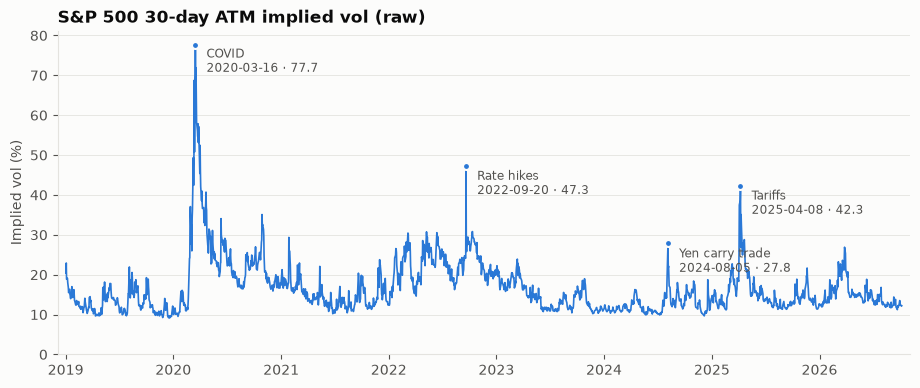

count    1952.0
mean       16.7
std         6.8
min         9.1
25%        12.2
50%        14.7
75%        19.2
max        77.7
Name: 100.0, dtype: float64

In [8]:
EPISODES = {
    "COVID": ("2020-02-15", "2020-05-31"),
    "Rate hikes": ("2022-01-01", "2022-12-31"),
    "Yen carry trade": ("2024-07-15", "2024-08-31"),
    "Tariffs": ("2025-03-15", "2025-05-15"),
}

def plot_atm(atm, title):
    fig, ax = plt.subplots(figsize=(11, 4.2))
    ax.plot(atm.index, atm, color=COLORS[0], linewidth=1.2)
    for name, (start, end) in EPISODES.items():
        window = atm.loc[start:end]
        date, value = window.idxmax(), window.max()
        ax.plot(date, value, "o", color=COLORS[0], markersize=5,
                markeredgecolor=SURFACE, markeredgewidth=1.5)
        ax.annotate(f"{name}\n{date:%Y-%m-%d} · {value:.1f}",
                    xy=(date, value), xytext=(8, -2), textcoords="offset points",
                    fontsize=8.5, color=INK_2, va="top")
    ax.set_title(title)
    ax.set_ylabel("Implied vol (%)")
    ax.set_ylim(0, None)
    ax.margins(x=0.01)
    plt.show()

atm = impvol[100.0]
plot_atm(atm, "S&P 500 30-day ATM implied vol (raw)")
atm.describe().round(1)

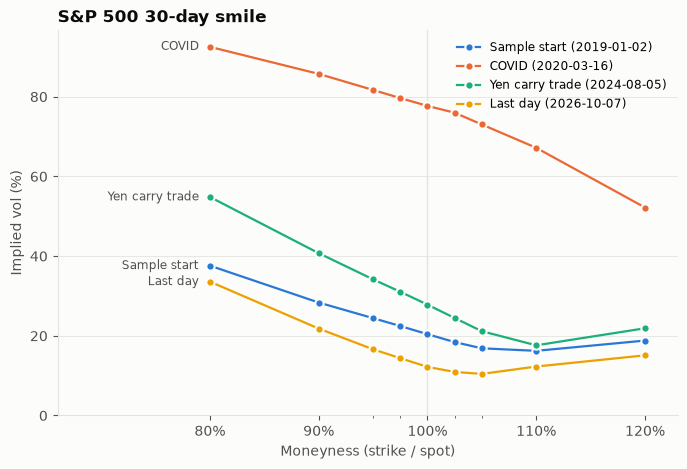

In [9]:
dates = {
    "2019-01-02": "Sample start",
    "2020-03-16": "COVID",
    "2024-08-05": "Yen carry trade",
    "2026-10-07": "Last day",
}
smiles = impvol.loc[list(dates)]

fig, ax = plt.subplots(figsize=(8, 5))
for (date, name), color in zip(dates.items(), COLORS):
    s = smiles.loc[date]
    ax.plot(s.index, s.values, color=color, marker="o", markersize=6,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label=f"{name} ({date})")
    ax.annotate(name, xy=(s.index[0], s.iloc[0]), xytext=(-8, 0), textcoords="offset points",
                ha="right", va="center", fontsize=8.5, color=INK_2)

ax.axvline(100, color=GRID, linewidth=1, zorder=0)
ax.set_xticks([80, 90, 100, 110, 120], labels=["80%", "90%", "100%", "110%", "120%"])
ax.set_xticks(impvol.columns, minor=True)
ax.set_xlim(66, 123)
ax.set_title("S&P 500 30-day smile")
ax.set_xlabel("Moneyness (strike / spot)")
ax.set_ylabel("Implied vol (%)")
ax.set_ylim(0, None)
ax.legend(loc="upper right", fontsize=8.5)
plt.show()

In [10]:
shape = pd.DataFrame({
    "atm": smiles[100.0],
    "skew_90": smiles[90.0] - smiles[100.0],
    "skew_90_rel": (smiles[90.0] - smiles[100.0]) / smiles[100.0],
    "wing_110": smiles[110.0] - smiles[100.0],
    "wing_120_110": smiles[120.0] - smiles[110.0],
})
shape.round(2)

,atm,skew_90,skew_90_rel,wing_110,wing_120_110
date,,,,,
2019-01-02,20.41,7.93,0.39,-4.19,2.58
2020-03-16,77.69,8.03,0.10,-10.51,-14.99
2024-08-05,27.82,12.92,0.46,-10.20,4.28
2026-10-07,12.20,9.61,0.79,0.08,2.81


In [11]:
def load_tenor(tenor):
    d = pd.read_csv(data_path / f"ovdv_impvol/SPX_IMPVOL_{tenor}.csv", parse_dates=True, index_col=0)
    d.columns = d.columns.str.extract(r"IMPVOL_([\d.]+)%")[0].astype(float)
    d.columns.name = "moneyness"
    return d

def neighbour_dev(s):
    return s - (s.shift(1) + s.shift(-1)) / 2

# a real move hits 30d and 60d together; a bad print only one of them
atm_60 = load_tenor("60DAY")[100.0]
mismatch = (neighbour_dev(impvol[100.0]) - neighbour_dev(atm_60)).abs()
mismatch.sort_values(ascending=False).head(6).round(1)

date
2022-09-20    21.8
2022-09-19    10.9
2022-09-21    10.7
2020-03-12     5.4
2020-03-13     4.9
2025-04-09     3.6
Name: 100.0, dtype: float64

In [ ]:
# looking for anomalies in the data
THRESHOLD = 15
bad_dates = mismatch[mismatch > THRESHOLD].index
print(bad_dates)
impvol.loc["2022-09-19":"2022-09-21"].round(1)

DatetimeIndex(['2022-09-20'], dtype='datetime64[us]', name='date', freq=None)


moneyness,80.0,90.0,95.0,97.5,100.0,102.5,105.0,110.0,120.0
date,,,,,,,,,
2022-09-19,38.5,29.3,26.7,25.5,24.2,22.6,21.2,19.9,21.1
2022-09-20,86.8,61.9,54.0,50.2,47.3,46.7,48.3,53.6,63.6
2022-09-21,41.2,31.9,29.2,28.0,26.7,25.2,23.5,21.5,23.1


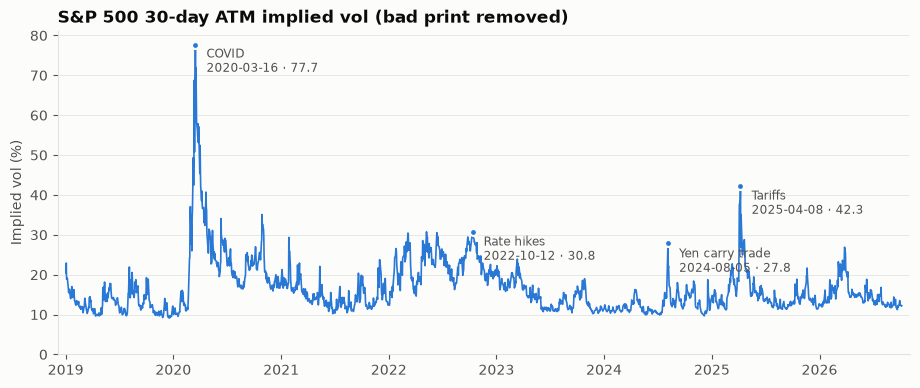

In [ ]:
# removing bad prints and interpolating
impvol_clean = impvol.copy()
impvol_clean.loc[bad_dates] = np.nan
impvol_clean = impvol_clean.interpolate(method="time")

plot_atm(impvol_clean[100.0], "S&P 500 30-day ATM implied vol (bad print removed)")

<Axes: xlabel='date'>

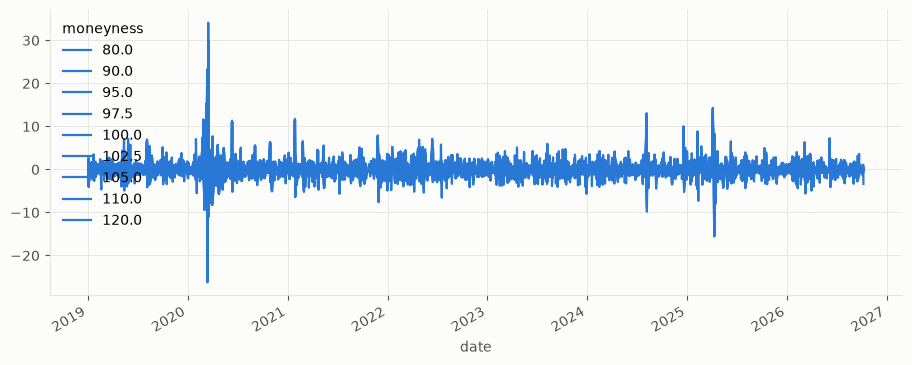

In [14]:
d_impvol = impvol_clean.diff().dropna()
d_impvol.plot(figsize=(11, 4.2), color=COLORS[0])

In [15]:
from statsmodels.tsa.stattools import adfuller
print(f"p-value: {adfuller(d_impvol[100.0], result_object=False)[1]}")

p-value: 4.3249471569267985e-19


In [16]:
rows = {}

for moneyness in impvol_clean.columns:
    rows[moneyness] = {
        "p_level": adfuller(impvol_clean[moneyness], result_object=False)[1],
        "p_diff": adfuller(d_impvol[moneyness], result_object=False)[1],
    }

adf = pd.DataFrame(rows).T

In [17]:
adf.round(4)

,p_level,p_diff
80.0,0.0002,0.0
90.0,0.0004,0.0
95.0,0.0007,0.0
97.5,0.0007,0.0
100.0,0.0006,0.0
102.5,0.0005,0.0
105.0,0.0003,0.0
110.0,0.0001,0.0
120.0,0.0000,0.0


In [18]:
phi = impvol_clean.apply(lambda s: s.autocorr(lag=1))
print(f"Autocorrelation: {phi}")
print(f"Half-life: {np.log(0.5) / np.log(phi)}")

Autocorrelation: moneyness
80.0     0.950178
90.0     0.957663
95.0     0.960113
97.5     0.959760
100.0    0.959114
102.5    0.958285
105.0    0.957318
110.0    0.940488
120.0    0.912301
dtype: float64
Half-life: moneyness
80.0     13.563029
90.0     16.022897
95.0     17.028946
97.5     16.876590
100.0    16.604031
102.5    16.267175
105.0    15.890837
110.0    11.297086
120.0     7.551822
dtype: float64


In [19]:
rows = {}

for moneyness in d_impvol.columns:
    rows[moneyness] = {
        "std": d_impvol[moneyness].std(),
        "skew": d_impvol[moneyness].skew(),
        "kurt": d_impvol[moneyness].kurtosis(),
        "min": d_impvol[moneyness].min(),
        "max": d_impvol[moneyness].max(),
    }

moments = pd.DataFrame(rows).T
moments

,std,skew,kurt,min,max
80.0,1.865006,2.109130,31.238291,-15.3305,23.9083
90.0,1.859654,2.131176,33.939653,-15.6605,24.4266
95.0,1.872871,2.004303,33.261021,-16.0845,24.8604
97.5,1.901718,1.945496,33.429977,-16.7207,25.5285
100.0,1.928509,2.002424,36.373865,-17.9838,26.9203
102.5,1.897416,2.289509,53.111840,-21.5478,28.8762
105.0,1.757960,2.883465,84.734196,-23.1207,30.3095
110.0,1.556576,4.714378,195.375073,-26.2576,34.0895
120.0,1.745533,1.064115,15.412658,-10.9891,21.4684


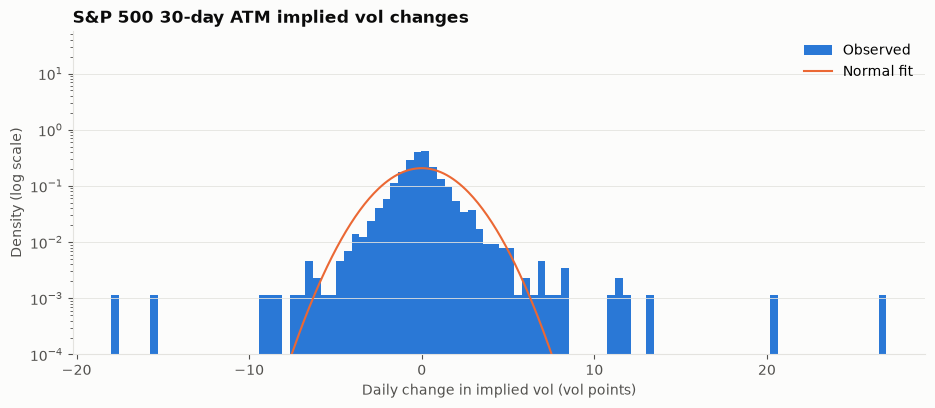

In [20]:
from scipy.stats import norm

atm_diff = d_impvol[100.0]
mu, std = atm_diff.mean(), atm_diff.std()
x = np.linspace(atm_diff.min(), atm_diff.max(), 500)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.hist(atm_diff, bins=100, density=True, color=COLORS[0], label="Observed")
ax.plot(x, norm.pdf(x, mu, std), color=COLORS[1], linewidth=1.5, label="Normal fit")
ax.set_yscale("log")
ax.set_ylim(1e-4, None)
ax.set_title("S&P 500 30-day ATM implied vol changes")
ax.set_xlabel("Daily change in implied vol (vol points)")
ax.set_ylabel("Density (log scale)")
ax.legend()
plt.show()


In [21]:
n_extreme = ((atm_diff - mu).abs() > 3 * std).sum()
n_normal = len(atm_diff) * 0.0027
print(f"Beyond 3 std: {n_extreme} days (normal would give {n_normal:.1f})")

Beyond 3 std: 32 days (normal would give 5.3)


In [22]:
top_110 = d_impvol[110.0].abs().nlargest(5).index
d_impvol.loc[top_110, 90.0:120.0].round(1)

moneyness,90.0,95.0,97.5,100.0,102.5,105.0,110.0,120.0
date,,,,,,,,
2020-03-16,24.4,24.9,25.5,26.9,28.9,30.3,34.1,21.5
2020-03-13,-15.7,-16.1,-16.7,-18.0,-21.5,-23.1,-26.3,-11.0
2020-03-12,20.3,20.0,20.0,20.2,22.3,22.7,23.3,11.2
2020-03-09,11.1,12.1,12.8,13.1,14.2,15.4,14.9,8.0
2025-04-09,-15.4,-15.5,-15.6,-15.5,-15.5,-15.5,-12.9,-4.1


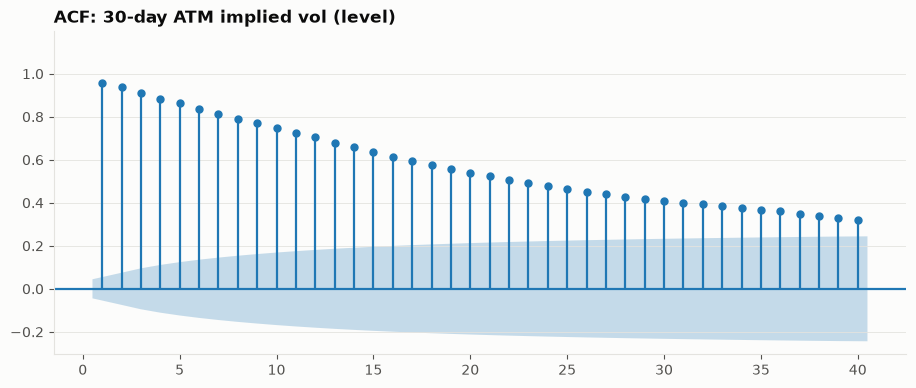

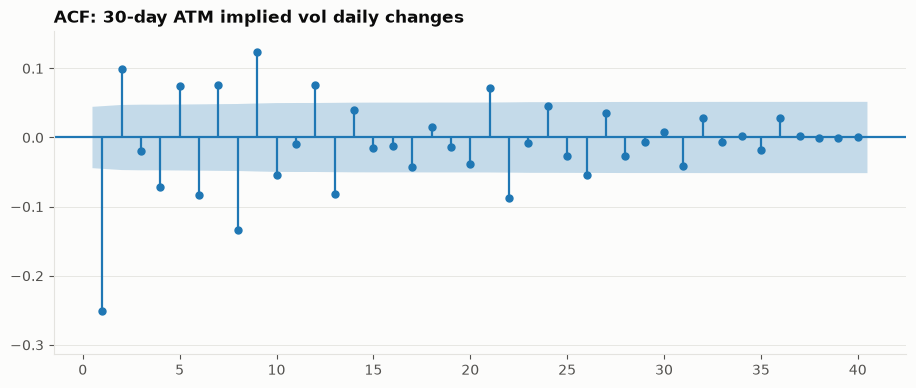

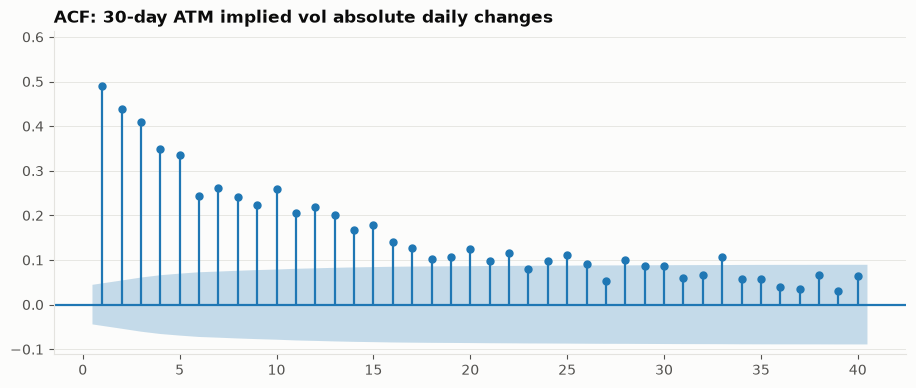

In [23]:
from statsmodels.graphics.tsaplots import plot_acf

def plot_acf_series(s, title):
    fig, ax = plt.subplots(figsize=(11, 4.2))
    plot_acf(s, lags=40, ax=ax, title=title, zero=False, auto_ylims=True)
    plt.show()

plot_acf_series(impvol_clean[100.0], "ACF: 30-day ATM implied vol (level)")
plot_acf_series(atm_diff, "ACF: 30-day ATM implied vol daily changes")
plot_acf_series(atm_diff.abs(), "ACF: 30-day ATM implied vol absolute daily changes")

In [24]:
lags = [1, 2, 3, 4, 5]
acf_diff = pd.DataFrame({lag: d_impvol.apply(lambda s: s.autocorr(lag=lag)) for lag in lags})
acf_diff.round(3)

,1,2,3,4,5
moneyness,,,,,
80.0,-0.218,0.052,-0.015,-0.070,0.058
90.0,-0.231,0.081,-0.020,-0.065,0.069
95.0,-0.231,0.089,-0.025,-0.059,0.069
97.5,-0.234,0.092,-0.026,-0.063,0.071
100.0,-0.251,0.099,-0.019,-0.071,0.075
102.5,-0.302,0.129,-0.003,-0.088,0.095
105.0,-0.360,0.167,0.017,-0.108,0.116
110.0,-0.482,0.219,0.063,-0.145,0.146
120.0,-0.370,0.027,-0.039,-0.023,0.079


In [25]:
print(f"Lag-1 ACF of ATM changes, full sample: {atm_diff.autocorr(lag=1):.3f}")
print(f"Lag-1 ACF of ATM changes, since 2021:  {atm_diff.loc['2021':].autocorr(lag=1):.3f}")

Lag-1 ACF of ATM changes, full sample: -0.251
Lag-1 ACF of ATM changes, since 2021:  -0.128


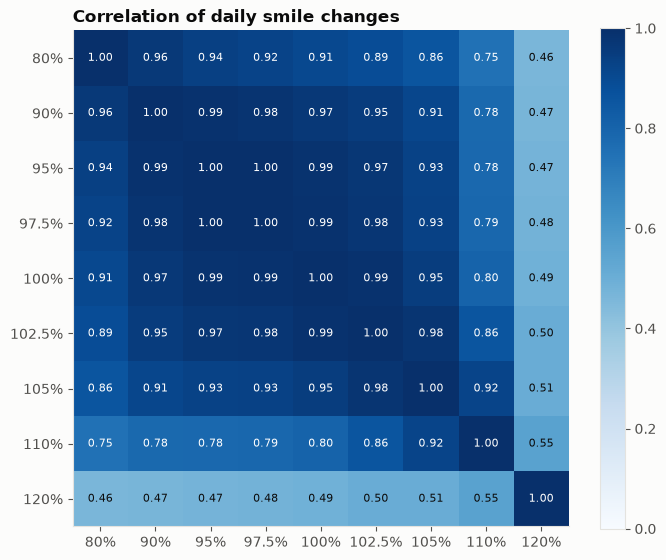

In [26]:
corr = d_impvol.corr()
labels = [f"{m:g}%" for m in corr.columns]

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(corr)), labels=labels)
ax.set_yticks(range(len(corr)), labels=labels)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if v > 0.7 else INK)
ax.set_title("Correlation of daily smile changes")
plt.colorbar(im, ax=ax)
plt.show()

In [27]:
from sklearn.decomposition import PCA
pca = PCA().fit(d_impvol)

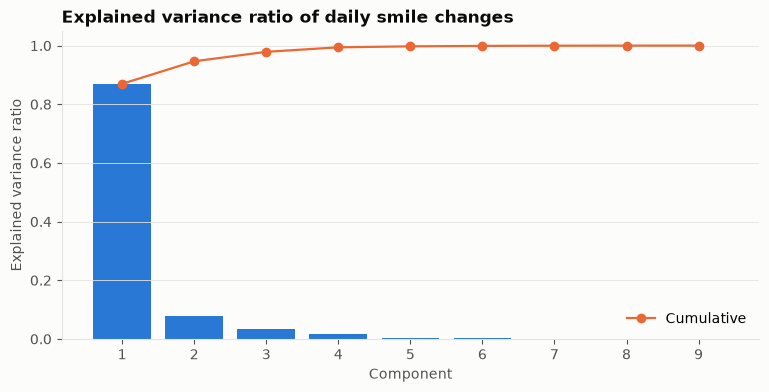

In [28]:
fig, ax = plt.subplots(figsize=(9, 4))
components = range(1, len(pca.explained_variance_ratio_) + 1)
ax.bar(components, pca.explained_variance_ratio_, color=COLORS[0])
ax.plot(components, pca.explained_variance_ratio_.cumsum(), marker="o", color=COLORS[1], label="Cumulative")
ax.set_xticks(components)
ax.set_title("Explained variance ratio of daily smile changes")
ax.set_xlabel("Component")
ax.set_ylabel("Explained variance ratio")
ax.legend()
plt.show()

In [29]:
pca.explained_variance_ratio_.cumsum()

array([0.86969434, 0.94653793, 0.9787902 , 0.99419163, 0.99751467,
       0.99903397, 0.99965335, 0.99992083, 1.        ])

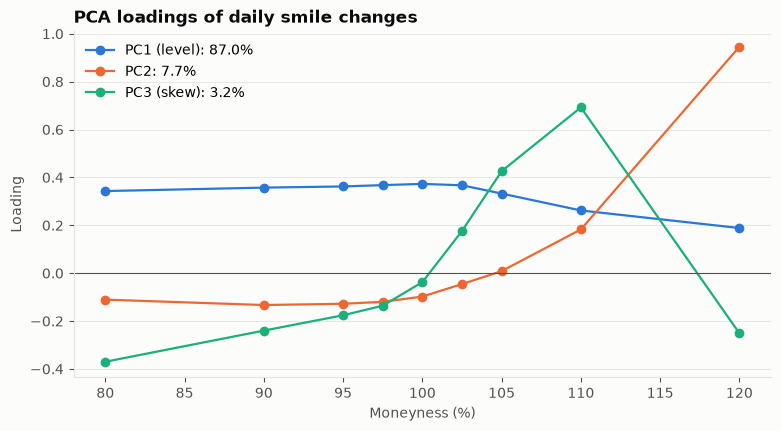

In [30]:
def plot_loadings(pca, columns, title):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for k, name in enumerate(["PC1 (level)", "PC2", "PC3 (skew)"]):
        ax.plot(columns, pca.components_[k], marker="o", color=COLORS[k],
                label=f"{name}: {pca.explained_variance_ratio_[k]:.1%}")
    ax.axhline(0, color=INK_2, linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Moneyness (%)")
    ax.set_ylabel("Loading")
    ax.legend()
    plt.show()

plot_loadings(pca, d_impvol.columns, "PCA loadings of daily smile changes")

In [31]:
pca_2021 = PCA().fit(d_impvol.loc["2021":])
pd.DataFrame({"full": pca.explained_variance_ratio_, "since_2021": pca_2021.explained_variance_ratio_},
             index=components).cumsum().head(4).round(3)

,full,since_2021
1,0.870,0.822
2,0.947,0.945
3,0.979,0.974
4,0.994,0.992


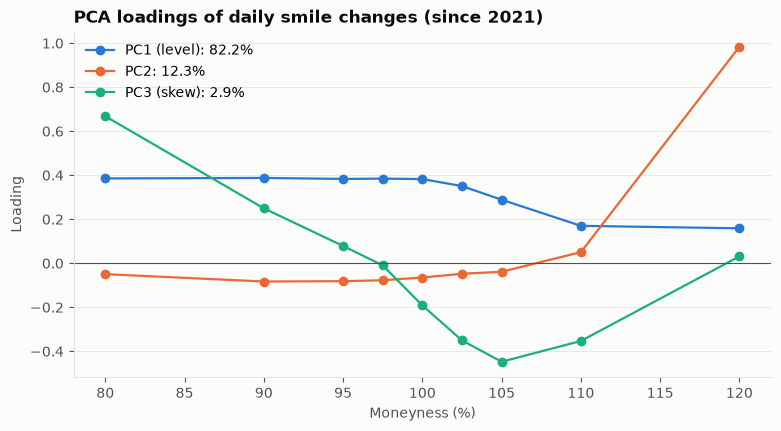

In [32]:
plot_loadings(pca_2021, d_impvol.columns, "PCA loadings of daily smile changes (since 2021)")